# ResPlan: from the raw release to model input

This notebook walks one dataset (ResPlan) through every stage of `Reconstruction/data_prep`:

1. **Raw release**: plans exactly as stored in `ResPlan.pkl` (Python dicts of Shapely geometries).
2. **Missing-component cases**: one plan, several different components removed one at a time.
3. **Raster representation**: the two instance layers and the 13-channel semantic maps.
4. **Network input**: the 28-channel tensor the conditional U-Net actually receives.

Needs the `metanoia` environment, `datasets/resplan/12/ResPlan.pkl` and `datasets/processed/resplan/`.
It never imports `torch`, so it starts quickly.

In [1]:
import sys
from collections import defaultdict
from pathlib import Path

# The notebook can live anywhere inside the repository.
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Reconstruction").is_dir())
sys.path.insert(0, str(REPO))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, PathPatch
from matplotlib.path import Path as MplPath
from shapely.geometry import Polygon

from Reconstruction.common.config_loader import load_params, load_run_config, resolve_path
from Reconstruction.data_prep.case_source import CaseSource, read_case_specs
from Reconstruction.data_prep.plan_store import PlanStore
from Reconstruction.data_prep.render import PANEL_TITLES, case_panels, render_semantic
from Reconstruction.data_prep.resplan_source import load_resplan_plans, load_split_ids

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

cfg = load_run_config(REPO / "Reconstruction/data_prep/config.toml", "prod")
SEED = cfg.SEED
PROCESSED = resolve_path(cfg.PROCESSED_ROOT) / "resplan"

# Frozen val/test cases and the taxonomy (classes, channels, colours) used at build time.
test_source = CaseSource(PROCESSED, "test", SEED)
schema = test_source.schema
COL = schema.colors
print("repo:", REPO)
print("processed data:", PROCESSED)

repo: /home/micml/26d0361/Metanoia
processed data: /home/micml/26d0361/Metanoia/datasets/processed/resplan


## 1. The original dataset, as extracted from the pickle

`load_resplan_plans` is a plain `pickle.load` (read-only). Nothing is converted yet.

In [2]:
raw_plans = load_resplan_plans(resolve_path(cfg.RESPLAN_PICKLE_PATH))
print("type(raw_plans) =", type(raw_plans).__name__, "| number of plans =", len(raw_plans))
print("type(raw_plans[0]) =", type(raw_plans[0]).__name__)

split_ids = load_split_ids(resolve_path(cfg.RESPLAN_SPLIT_PATH), include_augmented_in_train=False)
print({name: len(ids) for name, ids in split_ids.items()}, "<- official split, plan ids")

type(raw_plans) = list | number of plans = 17000
type(raw_plans[0]) = dict
{'train': 13053, 'val': 1632, 'test': 1632} <- official split, plan ids


In [3]:
by_id = {int(p["id"]): p for p in raw_plans}
rng = np.random.default_rng(SEED)
sample_ids = [int(i) for i in rng.choice(split_ids["test"], size=5, replace=False)]
print("5 random test plans (ids):", sample_ids)


def short(value, limit=110):
    text = repr(value)
    return text if len(text) <= limit else f"{text[:limit]} ... [{len(text)} chars]"


def show_raw(plan):
    print(f"type(plan) = {type(plan).__name__}, {len(plan)} keys")
    for key, value in plan.items():
        print(f"  {key!r:15} {type(value).__name__:13} {short(value)}")


for pid in sample_ids:
    print(f"\n================ plan id {pid} ================")
    show_raw(by_id[pid])

5 random test plans (ids): [13188, 7716, 11336, 1449, 7598]

================ plan id 13188 ================
type(plan) = dict, 20 keys
  'balcony'       Polygon       <POLYGON ((115.363 230.189, 156.238 230.189, 156.238 171.216, 115.363 171.21...>
  'bathroom'      MultiPolygon  <MULTIPOLYGON (((159.757 92.672, 159.757 130.254, 256 130.254, 256 92.672, 1...>
  'bedroom'       MultiPolygon  <MULTIPOLYGON (((159.757 226.67, 256 226.67, 256 132.923, 190.163 132.923, 1...>
  'door'          MultiPolygon  <MULTIPOLYGON (((160.607 140.013, 156.238 140.013, 156.238 161.543, 160.607 ...>
  'garden'        MultiPolygon  <MULTIPOLYGON EMPTY>
  'inner'         MultiPolygon  <MULTIPOLYGON (((2.22e-16 226.67, 111.844 226.67, 111.844 167.697, 159.757 1...>
  'parking'       MultiPolygon  <MULTIPOLYGON EMPTY>
  'pool'          MultiPolygon  <MULTIPOLYGON EMPTY>
  'wall'          MultiPolygon  <MULTIPOLYGON (((160.607 75.424, 156.238 75.424, 156.238 140.013, 160.607 14...>
  'window'        MultiPoly

What the raw keys are:

* **Geometry (Shapely `Polygon` / `MultiPolygon`)**: `wall`, `door`, `front_door`, `window`, the room types (`living`, `bedroom`, `bathroom`, `kitchen`, `storage`, `balcony`, `stair`), plus context keys `inner` (footprint), `land`, `garden`, `parking`, `pool`, `neighbor`. Missing keys mean the plan does not have that component.
* **Numbers**: `id`, `area` (m², floor area), `net_area`, `wall_depth`.
* **`graph`**: a `networkx` room-adjacency graph.
* Coordinates are normalised per plan to about a 256-unit square (not metres).

Raw plans plotted straight from these geometries (one colour per key):

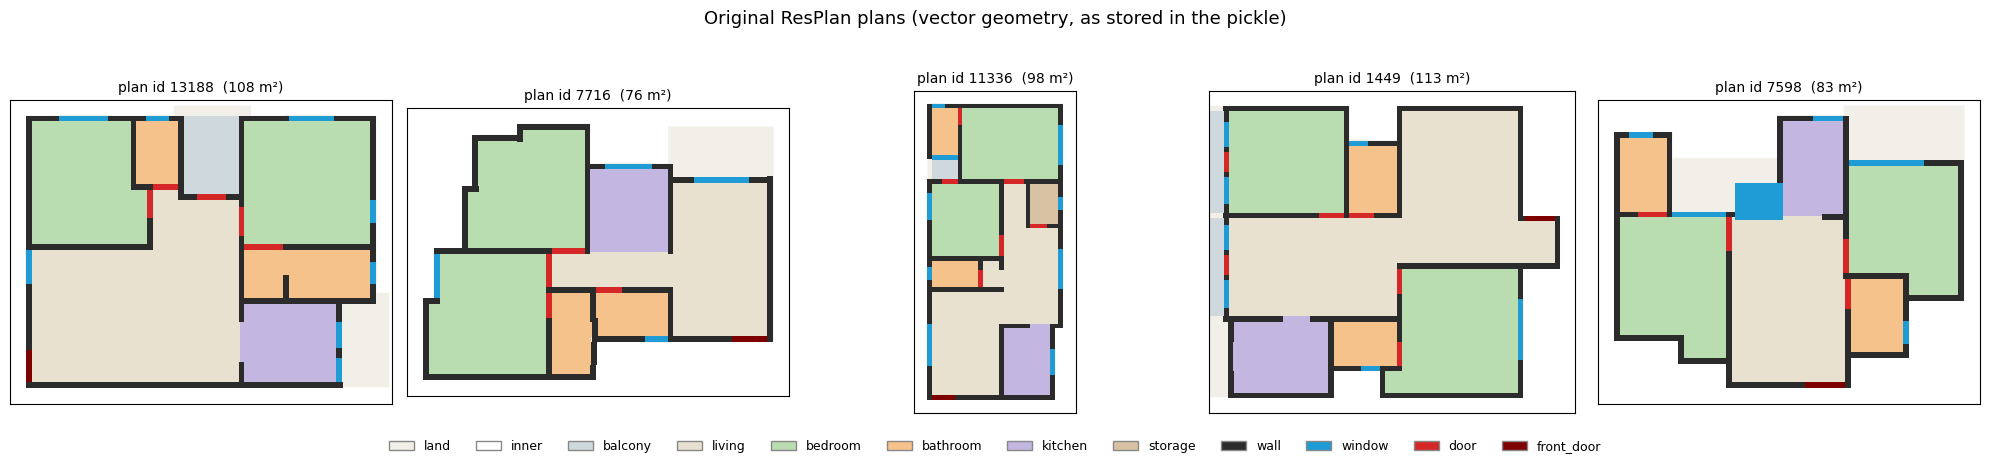

In [4]:
# (raw key, colour) in drawing order. Taxonomy colours are reused; context-only keys get neutral colours.
RAW_STYLE = [
    ("land", "#f2efe9"), ("inner", "#ffffff"), ("garden", "#c7e3b5"), ("parking", "#d0d0d0"), ("pool", "#a9d6f5"),
    ("balcony", COL["balcony"]), ("living", COL["living"]), ("bedroom", COL["bedroom"]), ("bathroom", COL["bathroom"]),
    ("kitchen", COL["kitchen"]), ("storage", COL["storage"]), ("stair", COL["stair"]),
    ("wall", COL["wall"]), ("window", COL["window"]), ("door", COL["door"]), ("front_door", "#7f0000"),
]


def polygons(geom):
    if geom is None or geom.is_empty:
        return []
    parts = getattr(geom, "geoms", [geom])
    return [g for g in parts if isinstance(g, Polygon) and not g.is_empty]


def polygon_patch(poly, **kwargs):
    rings = [poly.exterior, *poly.interiors]
    verts = np.concatenate([np.asarray(r.coords) for r in rings])
    codes = np.concatenate([[MplPath.MOVETO] + [MplPath.LINETO] * (len(r.coords) - 2) + [MplPath.CLOSEPOLY] for r in rings])
    return PathPatch(MplPath(verts, codes), **kwargs)


def draw_raw(ax, plan):
    # Returns the raw keys that were actually drawn (for the legend).
    drawn = []
    for key, colour in RAW_STYLE:
        parts = polygons(plan.get(key))
        for poly in parts:
            ax.add_patch(polygon_patch(poly, facecolor=colour, edgecolor="none", linewidth=0))
        if parts:
            drawn.append(key)
    minx, miny, maxx, maxy = plan["inner"].bounds
    pad = 0.06 * max(maxx - minx, maxy - miny)
    ax.set_xlim(minx - pad, maxx + pad)
    ax.set_ylim(miny - pad, maxy + pad)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    return drawn


def raw_legend(fig, keys):
    colour = dict(RAW_STYLE)
    handles = [Patch(facecolor=colour[k], edgecolor="#888888", label=k) for k, _ in RAW_STYLE if k in keys]
    fig.legend(handles=handles, loc="lower center", ncol=len(handles), fontsize=9, frameon=False)


fig, axes = plt.subplots(1, 5, figsize=(20, 4.6))
used = set()
for ax, pid in zip(axes, sample_ids):
    used |= set(draw_raw(ax, by_id[pid]))
    ax.set_title(f"plan id {pid}  ({by_id[pid]['area']:.0f} m²)", fontsize=10)
raw_legend(fig, used)
fig.suptitle("Original ResPlan plans (vector geometry, as stored in the pickle)", fontsize=13)
fig.tight_layout(rect=(0, 0.07, 1, 0.95))
plt.show()

## 2. Missing-component cases of one plan

A case = (plan, component to remove, mode, margin). `CaseSource.build(spec)` is the processing function: it takes the rasterized plan, removes the chosen component and returns the arrays.

* **easy**: erase only the chosen instance (a removed door/window leaves a gap in the wall; a removed room leaves an unlabelled area).
* **hard**: doors/windows are *filled with wall*, so the plan looks complete; for walls the doors/windows in that wall go too; for rooms, walls and openings touching no other room go too.

We take the first of the 5 plans above that has frozen test cases, and remove a wall, a door, a window and a room, one at a time, plus a hard-mode door.

In [5]:
frozen = read_case_specs(PROCESSED / "cases_test.jsonl")
specs_by_plan = defaultdict(list)
for spec in frozen:
    specs_by_plan[spec.plan_id].append(spec)

# Near-duplicates of train plans have no frozen cases, so take the first sampled plan that has some.
demo_plan_id = next((pid for pid in sample_ids if pid in specs_by_plan), next(iter(specs_by_plan)))
plan_specs = specs_by_plan[demo_plan_id]
print(f"chosen plan id {demo_plan_id}: {len(plan_specs)} frozen test cases")

WANTED = [("wall", "easy"), ("door", "easy"), ("window", "easy"), ("room", "easy"), ("door", "hard")]
chosen = []
for comp_type, mode in WANTED:
    match = [s for s in plan_specs if s.comp_type == comp_type and s.mode == mode and s.margin_px == 0]
    if match:
        chosen.append(match[0])
print("cases shown:", [s.case_id for s in chosen])

chosen plan id 13188: 8 frozen test cases
cases shown: ['test-13188-wall-s6-easy-m0', 'test-13188-door-s34-easy-m0', 'test-13188-window-s23-easy-m0', 'test-13188-room-r2-easy-m0', 'test-13188-door-s34-hard-m0']


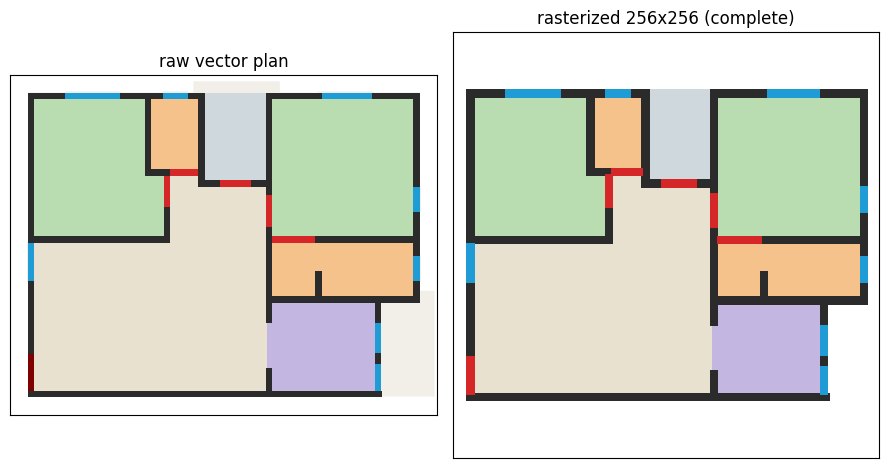

In [6]:
def show_cases(source, specs, title):
    # One row per case: complete | model input | missing part | erased region (same panels as visualize.py).
    fig, axes = plt.subplots(len(specs), len(PANEL_TITLES), squeeze=False, figsize=(3.3 * len(PANEL_TITLES), 3.3 * len(specs) + 1.3))
    cases = [source.build(spec) for spec in specs]
    for row, case in enumerate(cases):
        for col, panel in enumerate(case_panels(case, schema)):
            ax = axes[row, col]
            ax.imshow(panel, interpolation="nearest")
            ax.set_xticks([])
            ax.set_yticks([])
            if row == 0:
                ax.set_title(PANEL_TITLES[col], fontsize=11)
        info = case.info
        axes[row, 0].set_ylabel(f"{info['comp_type']} / {info['mode']}\n{info['primary_cls']}, {info['size_bin']}, {info['location']}", fontsize=9)
    handles = [Patch(color=COL[name], label=name) for name in schema.channels]
    handles.append(Patch(color=COL["mask_outline"], alpha=0.45, label="erased"))
    fig.legend(handles=handles, loc="lower center", ncol=len(handles), fontsize=8, frameon=False)
    fig.suptitle(title, fontsize=13)
    fig.tight_layout(rect=(0, 0.04, 1, 0.97))
    plt.show()
    return cases


# Raw vector plan next to its rasterized version (the 256x256 canvas the model works on).
case_list = [test_source.build(s) for s in chosen]
fig, (ax_raw, ax_raster) = plt.subplots(1, 2, figsize=(9, 4.6))
draw_raw(ax_raw, by_id[demo_plan_id])
ax_raw.set_title("raw vector plan")
ax_raster.imshow(render_semantic(case_list[0].full, schema), interpolation="nearest")
ax_raster.set_title("rasterized 256x256 (complete)")
ax_raster.set_xticks([])
ax_raster.set_yticks([])
fig.tight_layout()
plt.show()

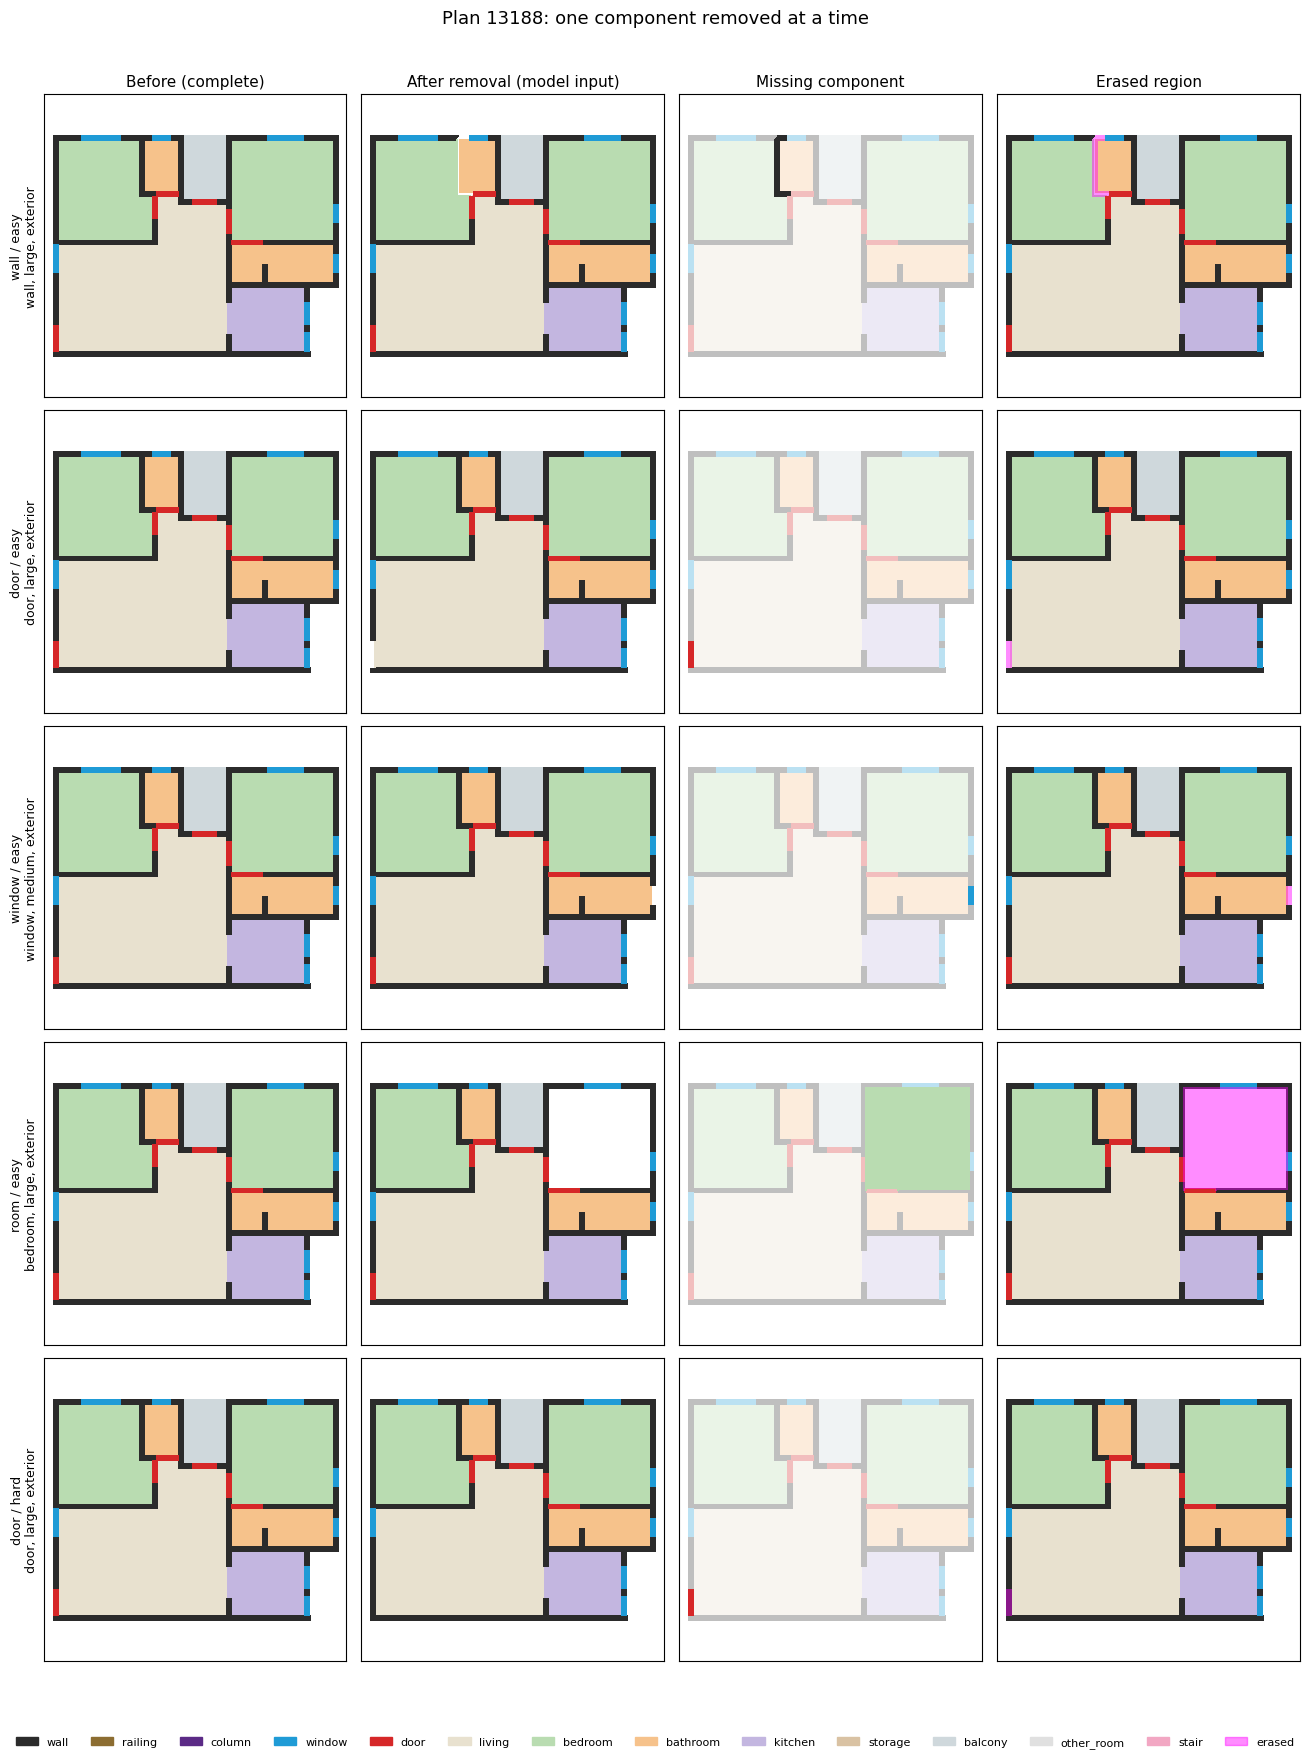

,case_id,type,mode,removed,target_px,size_bin,location,neighbours
0,test-13188-wall-s6-easy-m0,wall,easy,[wall],330,large,exterior,7
1,test-13188-door-s34-easy-m0,door,easy,[door],115,large,exterior,3
2,test-13188-window-s23-easy-m0,window,easy,[window],80,medium,exterior,3
3,test-13188-room-r2-easy-m0,room,easy,[bedroom],7722,large,exterior,12
4,test-13188-door-s34-hard-m0,door,hard,[door],115,large,exterior,3


In [7]:
cases = show_cases(test_source, chosen, f"Plan {demo_plan_id}: one component removed at a time")

rows = []
for case in cases:
    i = case.info
    rows.append({"case_id": i["case_id"], "type": i["comp_type"], "mode": i["mode"], "removed": [r["cls"] for r in i["removed"]],
                 "target_px": i["target_area_px"], "size_bin": i["size_bin"], "location": i["location"], "neighbours": i["num_neighbours"]})
pd.DataFrame(rows)

### Training cases are drawn on the fly

For val/test the cases are frozen (`cases_test.jsonl`). For **train**, a new random case is sampled every epoch: component type uniform over the types present, hard mode 30% of the time, margin 0/4/8/16 px. The same train plan, four epochs:

train plans: 13053
epoch 0: train-6-wall-s13-easy-m0
epoch 1: train-6-room-r4-easy-m0
epoch 2: train-6-window-s35-hard-m0
epoch 3: train-6-wall-s16-easy-m0


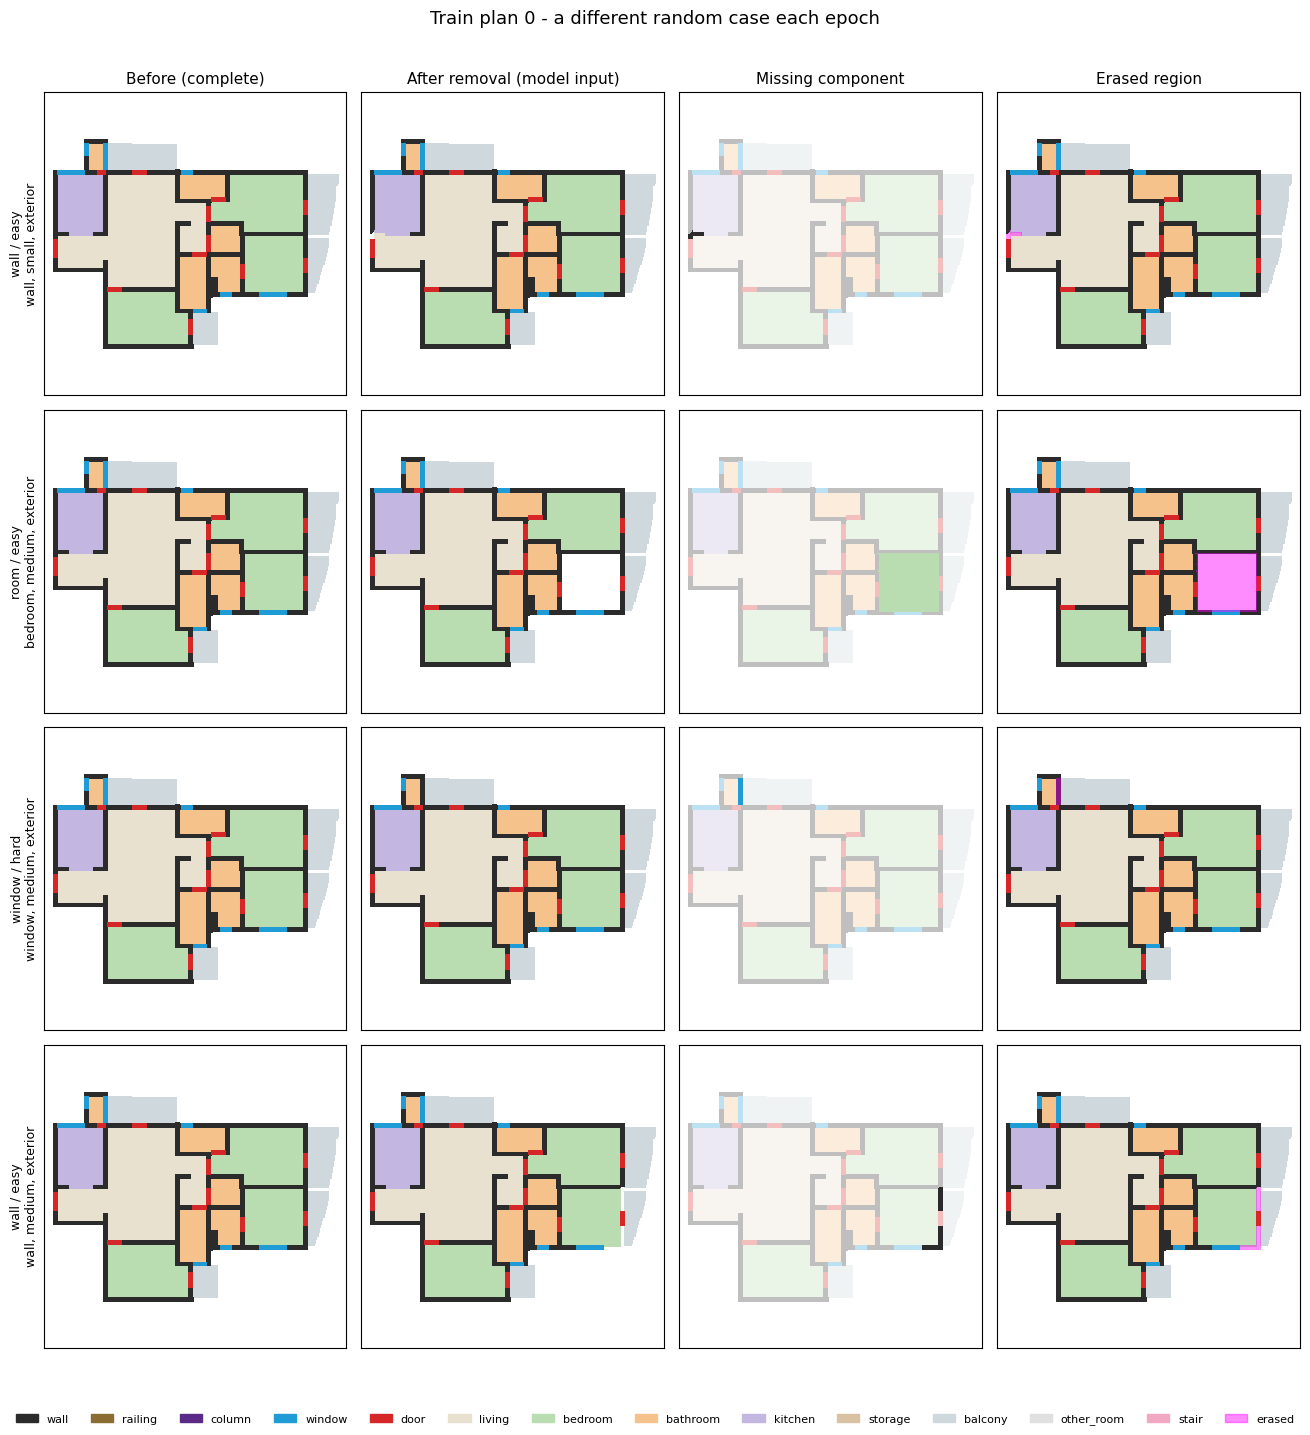

In [8]:
train_source = CaseSource(PROCESSED, "train", SEED)
print("train plans:", len(train_source))
epoch_specs = [train_source.spec(0, epoch) for epoch in range(4)]
for epoch, spec in enumerate(epoch_specs):
    print(f"epoch {epoch}: {spec.case_id}")
_ = show_cases(train_source, epoch_specs, "Train plan 0 - a different random case each epoch")

## 3. Rasterization: instance layers and 13 semantic channels

Each plan is fitted to a **256 x 256** canvas (8 px padding, aspect kept, north up) and stored as two `uint8` **instance layers** (pixel value = instance id, 0 = empty):

* `structure`: wall segments, railings, columns, windows, doors
* `room`: living, bedroom, bathroom, kitchen, storage, balcony, other_room, stair

The class of each instance id lives in the plan's record (`plans.jsonl`).

In [9]:
for split in ("train", "val", "test"):
    room = np.load(PROCESSED / split / "room.npy", mmap_mode="r")
    structure = np.load(PROCESSED / split / "structure.npy", mmap_mode="r")
    print(f"{split:5} room.npy {room.shape} {room.dtype} | structure.npy {structure.shape} {structure.dtype}")

store = PlanStore(PROCESSED / "test")
plan_index = chosen[0].plan_index
layers = store.layers(plan_index)
record = store.record(plan_index)
print(f"\nplan id {record['plan_id']} (test index {plan_index}): metres_per_px = {record['metres_per_px']:.4f}, {len(record['instances'])} instances")
instances = pd.DataFrame([{k: v for k, v in inst.items() if k != "polygon"} for inst in record["instances"]])
display(instances.head(12))
print(instances.groupby("cls").size().rename("instances per class").to_frame().T)

train room.npy (13053, 256, 256) uint8 | structure.npy (13053, 256, 256) uint8
val   room.npy (1632, 256, 256) uint8 | structure.npy (1632, 256, 256) uint8
test  room.npy (1632, 256, 256) uint8 | structure.npy (1632, 256, 256) uint8

plan id 13188 (test index 1260): metres_per_px = 0.0530, 41 instances


,layer,id,cls,area_px,bbox
0,structure,1,wall,1050,"[35, 8, 128, 96]"
1,structure,2,wall,424,"[35, 154, 92, 188]"
2,structure,3,wall,81,"[35, 65, 40, 83]"
3,structure,4,wall,426,"[35, 107, 97, 159]"
4,structure,5,wall,410,"[35, 220, 93, 249]"
5,structure,6,wall,330,"[35, 80, 87, 95]"
6,structure,7,wall,79,"[109, 244, 126, 249]"
7,structure,8,wall,209,"[118, 154, 162, 159]"
8,structure,9,wall,346,"[123, 185, 135, 249]"
9,structure,10,wall,81,"[144, 184, 161, 189]"


cls                  balcony  bathroom  bedroom  door  kitchen  living  wall  window
instances per class        1         2        2     6        1       1    20       8


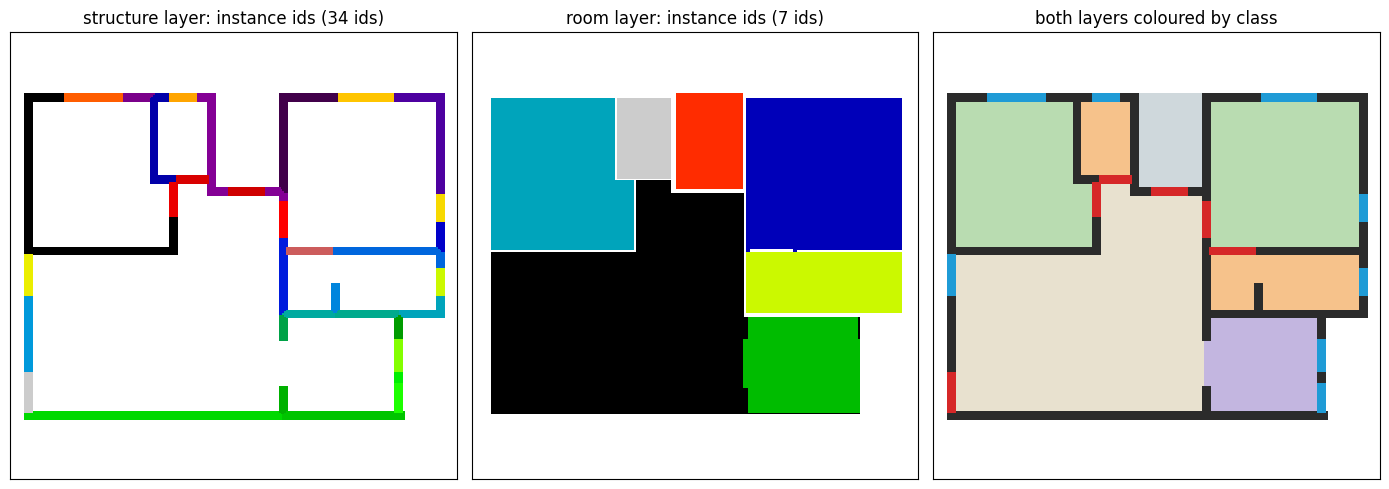

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.8))
for ax, name in zip(axes[:2], ("structure", "room")):
    layer = np.ma.masked_equal(layers[name], 0)
    ax.imshow(layer, cmap="nipy_spectral", interpolation="nearest")
    ax.set_title(f"{name} layer: instance ids ({len(np.unique(layer.compressed()))} ids)")
axes[2].imshow(render_semantic(case_list[0].full, schema), interpolation="nearest")
axes[2].set_title("both layers coloured by class")
for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
fig.tight_layout()
plt.show()

### What each of the 13 channels means

`full`, `incomplete` and `target` are multi-hot maps with `C = 13` channels (value 1 = that class is present at the pixel). Channel order = structure classes first, then room classes (`params.toml [taxonomy]`). A pixel can be in several channels, e.g. a room pixel under a wall.

,class,instance layer,component type,colour,meaning
channel,,,,,
0,wall,structure,wall,#2b2b2b,wall segments (walls stop at door/window openi...
1,railing,structure,other,#8c6d31,railings (CubiCasa5K only; always empty in Res...
2,column,structure,other,#5b2a86,columns (CubiCasa5K only; always empty in ResP...
3,window,structure,window,#1f9bd6,window openings
4,door,structure,door,#d62728,door openings (door and front_door)
5,living,room,room,#e8e1cf,living / dining area
6,bedroom,room,room,#b9dcb1,bedroom
7,bathroom,room,room,#f6c28b,bathroom
8,kitchen,room,room,#c3b6e0,kitchen


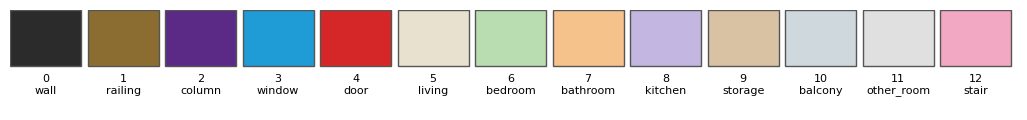

In [11]:
MEANING = {
    "wall": "wall segments (walls stop at door/window openings)",
    "railing": "railings (CubiCasa5K only; always empty in ResPlan)",
    "column": "columns (CubiCasa5K only; always empty in ResPlan)",
    "window": "window openings",
    "door": "door openings (door and front_door)",
    "living": "living / dining area",
    "bedroom": "bedroom",
    "bathroom": "bathroom",
    "kitchen": "kitchen",
    "storage": "storage room / closet",
    "balcony": "balcony",
    "other_room": "unclassified room (CubiCasa5K only; always empty in ResPlan)",
    "stair": "staircase",
}
channel_table = pd.DataFrame({
    "channel": range(schema.num_channels),
    "class": schema.channels,
    "instance layer": [schema.layer_of(n) for n in schema.channels],
    "component type": [schema.component_type[n] for n in schema.channels],
    "colour": [COL[n] for n in schema.channels],
    "meaning": [MEANING[n] for n in schema.channels],
})
display(channel_table.set_index("channel"))

fig, ax = plt.subplots(figsize=(13, 1.3))
for i, name in enumerate(schema.channels):
    ax.add_patch(plt.Rectangle((i, 0), 0.92, 1, facecolor=COL[name], edgecolor="#555555"))
    ax.text(i + 0.46, -0.15, f"{i}\n{name}", ha="center", va="top", fontsize=8)
ax.set_xlim(0, schema.num_channels)
ax.set_ylim(-0.8, 1)
ax.axis("off")
plt.show()

### Arrays of one case

The case below is the first one above (a removed wall segment, easy mode). With `F` = full, `I` = incomplete, `R` = target (missing part): `R = F AND NOT I`. Only `I` is given to the model at test time; `mask` and `primary` are for oracle baselines and metrics.

In [12]:
case0 = case_list[0]
print("case:", case0.info["case_id"])
for name in ("full", "incomplete", "target", "mask", "primary"):
    arr = getattr(case0, name)
    print(f"{name:11} shape={str(arr.shape):16} dtype={arr.dtype}  nonzero={int((arr > 0).sum())}")
print("F == I OR R :", bool(((case0.incomplete | case0.target) == case0.full).all()))

counts = pd.DataFrame({
    "class": schema.channels,
    "full (F)": case0.full.sum(axis=(1, 2)),
    "incomplete (I)": case0.incomplete.sum(axis=(1, 2)),
    "target (R)": case0.target.sum(axis=(1, 2)),
}).set_index("class")
display(counts.T)

case: test-13188-wall-s6-easy-m0
full        shape=(13, 256, 256)   dtype=uint8  nonzero=47384
incomplete  shape=(13, 256, 256)   dtype=uint8  nonzero=47054
target      shape=(13, 256, 256)   dtype=uint8  nonzero=330
mask        shape=(256, 256)       dtype=uint8  nonzero=330
primary     shape=(256, 256)       dtype=uint8  nonzero=330
F == I OR R : True


class,wall,railing,column,window,door,living,bedroom,bathroom,kitchen,storage,balcony,other_room,stair
full (F),5461,0,0,870,654,15838,14339,4541,3591,0,2090,0,0
incomplete (I),5131,0,0,870,654,15838,14339,4541,3591,0,2090,0,0
target (R),330,0,0,0,0,0,0,0,0,0,0,0,0


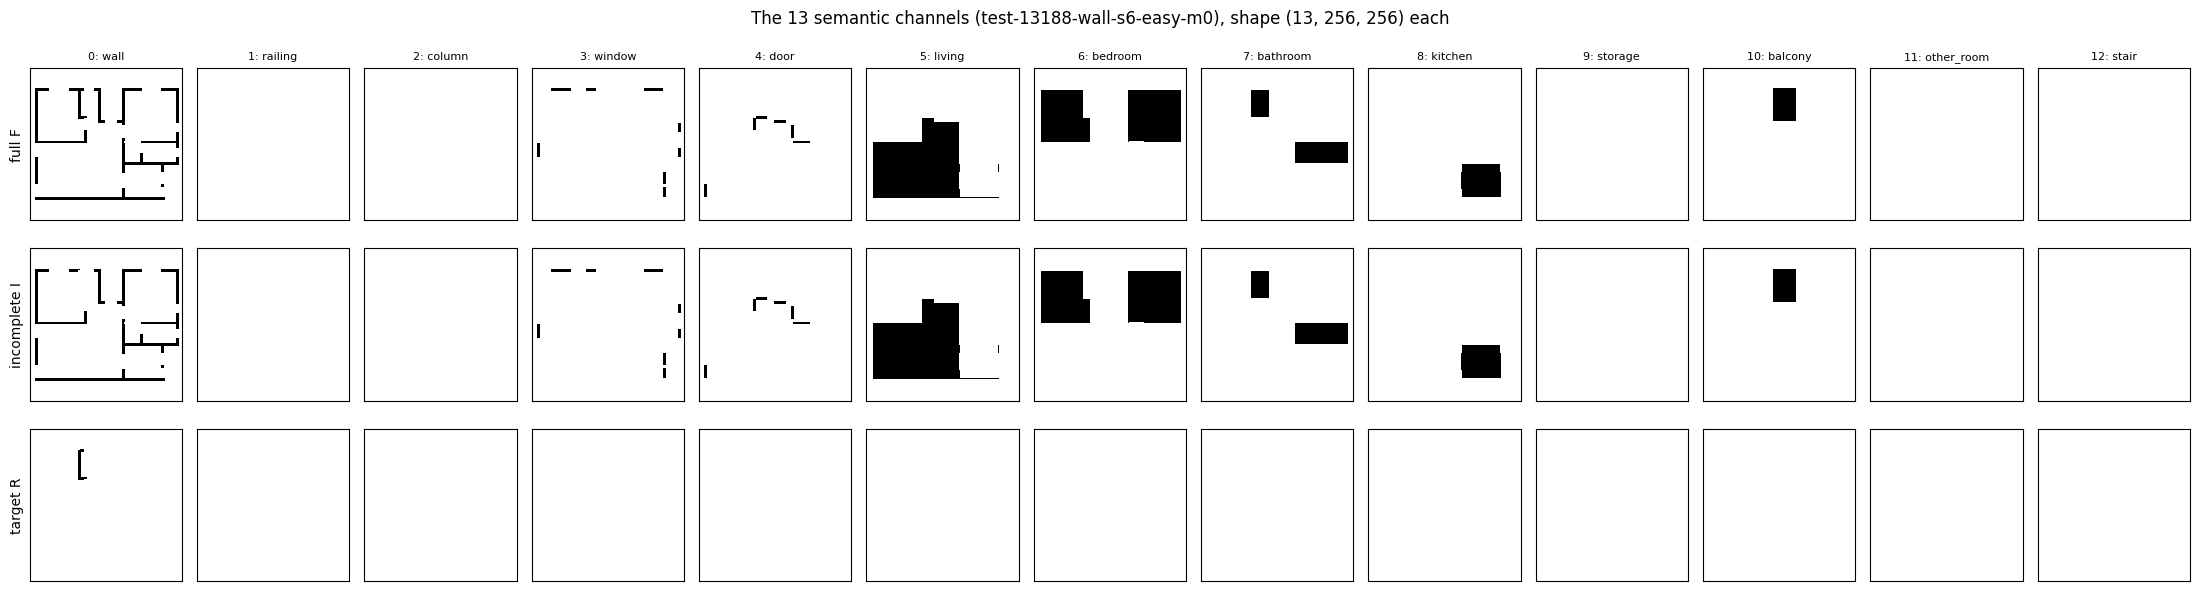

In [13]:
# Every channel of F, I and R as a binary image; the removed component only changes the target's channel(s).
fig, axes = plt.subplots(3, schema.num_channels, figsize=(1.7 * schema.num_channels, 6.2))
for row, (label, array) in enumerate((("full F", case0.full), ("incomplete I", case0.incomplete), ("target R", case0.target))):
    for ch in range(schema.num_channels):
        ax = axes[row, ch]
        ax.imshow(array[ch], cmap="gray_r", vmin=0, vmax=1, interpolation="nearest")
        ax.set_xticks([])
        ax.set_yticks([])
        if row == 0:
            ax.set_title(f"{ch}: {schema.channels[ch]}", fontsize=8)
        if ch == 0:
            ax.set_ylabel(label, fontsize=10)
fig.suptitle(f"The 13 semantic channels ({case0.info['case_id']}), shape (13, 256, 256) each", fontsize=12)
fig.tight_layout()
plt.show()

## 4. What the network receives: 256 x 256 x 28

The stored arrays have **13** channels, and that is also what the test-time input plan `I` has. The conditional U-Net's first convolution takes **28** channels, built from three groups:

| channels | content | training | test time |
|---|---|---|---|
| 0-12 | `x_t`: the target `R` (scaled to {-1, +1}) after adding noise for timestep `t` | noised `R` at a random `t` | pure Gaussian noise (`t = T-1`), denoised step by step |
| 13-25 | condition: the incomplete plan `I`, scaled to {-1, +1} | same | same |
| 26-27 | `y` and `x` coordinate maps in [-1, 1] (`USE_COORDINATES = true`) | same | same |

The network outputs 13 channels again (the missing part). The cosine schedule below is the one in `model/diffusion.py`, re-written in NumPy so this notebook does not need `torch`.

In [14]:
try:
    hyper = load_params(REPO / "Reconstruction/model/hyperparameters.toml")
    T, MAX_BETA, USE_COORDINATES = hyper.diffusion.TIMESTEPS, hyper.diffusion.MAX_BETA, hyper.model.USE_COORDINATES
except Exception as error:  # hyperparameters.toml unreadable: use the values it is meant to hold
    print("could not read hyperparameters.toml, using its documented values:", error)
    T, MAX_BETA, USE_COORDINATES = 1000, 0.999, True
print("timesteps:", T, "| max beta:", MAX_BETA, "| use coordinates:", USE_COORDINATES)
assert USE_COORDINATES, "this notebook shows the 28-channel input (13 + 13 + 2 coordinates)"


def cosine_alpha_bar(timesteps, max_beta, offset=0.008):
    f = lambda t: np.cos((t / timesteps + offset) / (1 + offset) * np.pi / 2) ** 2
    betas = [min(1 - f(i + 1) / f(i), max_beta) for i in range(timesteps)]
    return np.cumprod(1 - np.array(betas, dtype=np.float64))


alpha_bar = cosine_alpha_bar(T, MAX_BETA)
size = case0.full.shape[-1]

x0 = 2.0 * case0.target.astype(np.float32) - 1.0           # (13, 256, 256) in {-1, +1}
condition = 2.0 * case0.incomplete.astype(np.float32) - 1.0  # (13, 256, 256) in {-1, +1}
axis = np.linspace(-1.0, 1.0, size, dtype=np.float32)
coord_y, coord_x = np.meshgrid(axis, axis, indexing="ij")
coords = np.stack([coord_y, coord_x])                       # (2, 256, 256)

noise_rng = np.random.default_rng(SEED)
eps = noise_rng.standard_normal(x0.shape).astype(np.float32)


def network_input(t):
    # x_t = sqrt(alpha_bar_t) * x0 + sqrt(1 - alpha_bar_t) * eps
    x_t = np.sqrt(alpha_bar[t]) * x0 + np.sqrt(1 - alpha_bar[t]) * eps
    return np.concatenate([x_t, condition, coords]).astype(np.float32)


sample = network_input(t=400)
print("network input at t=400:", sample.shape, sample.dtype, "(C, H, W); as a batch tensor: (B, 28, 256, 256)")
print("range per group:", {"x_t": (round(float(sample[:13].min()), 2), round(float(sample[:13].max()), 2)),
                           "condition": (float(sample[13:26].min()), float(sample[13:26].max())),
                           "coords": (float(sample[26:].min()), float(sample[26:].max()))})

names = [f"x_t[{n}]" for n in schema.channels] + [f"cond[{n}]" for n in schema.channels] + ["coord_y", "coord_x"]
pd.DataFrame({"input channel": range(28), "content": names}).set_index("input channel").T

could not read hyperparameters.toml, using its documented values: Expected '=' after a key in a key/value pair (at line 5, column 7)
timesteps: 1000 | max beta: 0.999 | use coordinates: True
network input at t=400: (28, 256, 256) float32 (C, H, W); as a batch tensor: (B, 28, 256, 256)
range per group: {'x_t': (-3.74, 2.85), 'condition': (-1.0, 1.0), 'coords': (-1.0, 1.0)}


input channel,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27
content,x_t[wall],x_t[railing],x_t[column],x_t[window],x_t[door],x_t[living],x_t[bedroom],x_t[bathroom],x_t[kitchen],x_t[storage],x_t[balcony],x_t[other_room],x_t[stair],cond[wall],cond[railing],cond[column],cond[window],cond[door],cond[living],cond[bedroom],cond[bathroom],cond[kitchen],cond[storage],cond[balcony],cond[other_room],cond[stair],coord_y,coord_x


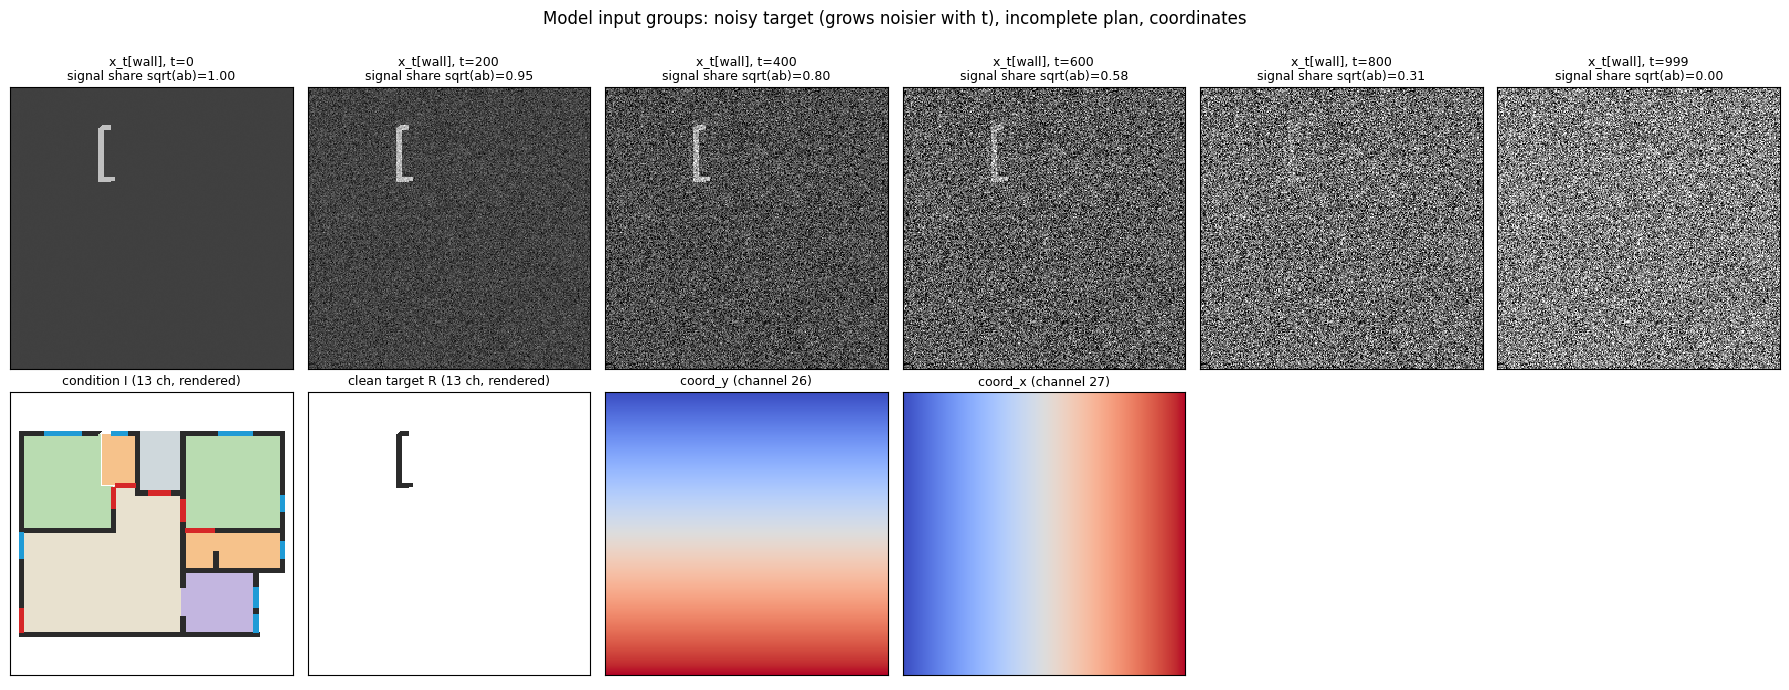

In [15]:
# The noisy target of the removed class at several timesteps, then the other inputs.
ch = int(case0.target.sum(axis=(1, 2)).argmax())
timesteps = [0, 200, 400, 600, 800, T - 1]
fig, axes = plt.subplots(2, len(timesteps), figsize=(3.0 * len(timesteps), 7.0))
for ax, t in zip(axes[0], timesteps):
    ax.imshow(network_input(t)[ch], cmap="gray", vmin=-2, vmax=2, interpolation="nearest")
    ax.set_title(f"x_t[{schema.channels[ch]}], t={t}\nsignal share sqrt(ab)={np.sqrt(alpha_bar[t]):.2f}", fontsize=9)
bottom = [
    (render_semantic(case0.incomplete, schema), "condition I (13 ch, rendered)"),
    (render_semantic(case0.target, schema), "clean target R (13 ch, rendered)"),
    (coord_y, "coord_y (channel 26)"),
    (coord_x, "coord_x (channel 27)"),
]
for ax, (img, title) in zip(axes[1], bottom):
    ax.imshow(img, cmap="coolwarm" if img.ndim == 2 else None, interpolation="nearest")
    ax.set_title(title, fontsize=9)
for ax in axes[1][len(bottom):]:
    ax.axis("off")
for ax in axes.ravel():
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle("Model input groups: noisy target (grows noisier with t), incomplete plan, coordinates", fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.96), h_pad=2.5)
plt.show()

## Summary of the shapes

| stage | object | shape / type |
|---|---|---|
| raw | `ResPlan.pkl` | `list` of 17,000 `dict` (Shapely geometries + `id`, `area`, `graph`, ...) |
| raster | `room.npy`, `structure.npy` (per split) | `uint8 (N, 256, 256)` instance ids |
| case | `full`, `incomplete`, `target` | `uint8 (13, 256, 256)`, multi-hot |
| case | `mask`, `primary` | `uint8 (256, 256)` |
| model input | `[x_t, I, y, x]` | `float32 (28, 256, 256)` (13 + 13 + 2) |
| model output | predicted missing part | 13 channels `(13, 256, 256)` |
| final plan | `I + R_hat` | 13 channels `(13, 256, 256)` |